# BT4012 Competition — Supervised Learning

Continues from `02_preprocessing.ipynb`. Trains on the 31,235 transactions with a genuine label and predicts `test.csv` (`time_step` 36–49, all later than anything in `train`). The competition metric is **ROC-AUC**, so every score here is ROC-AUC.

Every choice in this notebook is made on **our own validation only**; the leaderboard is never used to choose. The steps:
1. **Setup**: two temporal validation splits and the sample weights every model uses.
2. **Baseline**: Logistic Regression (not tuned; it is the reference every candidate should beat), also used to test whether the pseudo-labels from `02_preprocessing.ipynb` should be added to the training data.
3. **Candidate models**: Random Forest, LightGBM, XGBoost and a neural network (MLP), with their default settings.
4. **Tuning every candidate**: a hyperparameter search for each model, kept only if it helps on both splits.
5. **Model choice**: the tuned model with the best average ROC-AUC over the two splits.
6. **Feature removal by SHAP**: drop the features the chosen model barely uses, if that helps on both splits.
7. **Half-life tuning**: the recency half-life tuned together with the chosen model's settings.
8. **Final model**: retrained on all labeled rows, written to `data/submissions/final_submission.csv`, and explained with SHAP. The tuned settings of every model are also saved for `04_ensemble.ipynb`.

In [1]:
import itertools
import json
import warnings

from lightgbm import LGBMClassifier
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 20)

## 1. Setup

### Data
The reduced feature set from `02_preprocessing.ipynb`: 85 features (74 anonymized, 11 graph). `time_step` is never a model input: every test row's `time_step` lies outside the training range.

In [2]:
train_reduced = pd.read_csv("data/processed/train_reduced.csv")
test_reduced = pd.read_csv("data/processed/test_reduced.csv")

# Model features: everything except the identifier, the time step, the label, and the pseudo-label columns
# from 02_preprocessing.ipynb (candidate extra training rows, tested in step 2, never features).
feat_cols = [c for c in train_reduced.columns
             if c not in ("txId", "time_step", "label", "label_propagated", "label_propagated_confidence")]

labeled = train_reduced[train_reduced["label"].notna()].copy()
labeled["label"] = labeled["label"].astype(int)

print("model features:", len(feat_cols))
print("labeled rows:", len(labeled), f"(illicit {labeled['label'].mean():.2%})")
print("test rows:", len(test_reduced))

model features: 85
labeled rows: 31235 (illicit 11.67%)
test rows: 15329


### Validation splits
The test set lies strictly after the training data, so validation always trains on earlier time steps and scores later ones. Random k-fold cross-validation is never used: it would train on later transactions and score earlier ones.

- **Adjacent**: train on `time_step` 1–30, validate on 31–35 (predicting 1–5 steps ahead).
- **Gap-matched**: train on 1–20, validate on 30–35 (10–15 steps ahead). The real test set lies 1–14 steps after training, so this split is closer to the real task; the adjacent split alone scores ROC-AUC ≈ 0.998 for most models and can barely tell them apart.

### Sample weights
Every model gets the same weight per training row, the product of:
- **Class weight**: illicit rows count (licit rows ÷ illicit rows), about 7.6; licit rows count 1, so both classes contribute equally.
- **Recency weight** `0.5 ** ((T - t) / 10)`: `t` is the row's `time_step`, `T` the latest `time_step` in that training set (30, 20, or 35 for the final model). The newest rows count 1, halving every 10 steps back, because illicit behaviour drifts over time (shown below). A half-life of 10 is the shared starting value for comparing models; it is tuned together with the chosen model's other settings in step 7.

In [3]:
SPLITS = {
    "adjacent": (labeled[labeled["time_step"] <= 30], labeled[labeled["time_step"].between(31, 35)]),
    "gap-matched": (labeled[labeled["time_step"] <= 20], labeled[labeled["time_step"].between(30, 35)]),
}
for name, (tr, va) in SPLITS.items():
    print(f"{name}: train {len(tr)} rows, validate {len(va)} rows ({va['label'].sum()} illicit)")

HALF_LIFE = 10


def sample_weight(rows, half_life=HALF_LIFE):
    y = rows["label"]
    weight = y.map({0: 1.0, 1: (y == 0).sum() / (y == 1).sum()})
    if half_life is not None:  # None = class weight only, no recency weighting
        weight = weight * 0.5 ** ((rows["time_step"].max() - rows["time_step"]) / half_life)
    return weight.to_numpy()


def evaluate(fit_predict, cols_by_split=None):
    # fit_predict(train_rows, val_rows, cols) -> P(illicit) for val_rows. Returns ROC-AUC per split, their
    # average, and illicit precision / recall / F1 at a 0.5 threshold on the adjacent split.
    scores = {}
    for name, (tr, va) in SPLITS.items():
        cols = cols_by_split[name] if cols_by_split else feat_cols
        proba = fit_predict(tr, va, cols)
        scores[name] = roc_auc_score(va["label"], proba)
        if name == "adjacent":
            p, r, f, _ = precision_recall_fscore_support(va["label"], proba >= 0.5, average="binary")
            scores.update({"precision (adjacent)": p, "recall (adjacent)": r, "F1 (adjacent)": f})
    scores["average"] = (scores["adjacent"] + scores["gap-matched"]) / 2
    return scores

adjacent: train 26905 rows, validate 4330 rows (690 illicit)
gap-matched: train 18889 rows, validate 4854 rows (773 illicit)


### Why weight by recency: the data drifts over time

If the features looked the same in every period, a classifier could not tell early transactions from late ones. Here a Random Forest is trained to separate `time_step` ≤ 30 from > 30 using **only the features** (no labels), scored on a random 30% held out. A ROC-AUC near 0.5 would mean no drift; near 1.0 means the periods look clearly different. Its feature importances show which features reveal the period most.

In [4]:
period = (labeled["time_step"] > 30).astype(int)  # 1 = late, 0 = early
X_a, X_b, p_a, p_b = train_test_split(labeled[feat_cols], period, test_size=0.3, stratify=period, random_state=42)
period_clf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_a, p_a)
print(f"early vs. late ROC-AUC from features alone: {roc_auc_score(p_b, period_clf.predict_proba(X_b)[:, 1]):.4f}")
drift_importance = pd.Series(period_clf.feature_importances_, index=feat_cols).sort_values(ascending=False)
print("\nfeatures that reveal the period most:")
print(drift_importance.head(5).round(3).to_string())

early vs. late ROC-AUC from features alone: 1.0000

features that reveal the period most:
feat_136    0.328
feat_103    0.316
feat_2      0.069
feat_142    0.033
feat_112    0.032


## 2. Baseline: Logistic Regression

A linear model on standardized features (the scaler is fitted on the training rows only). Every candidate below should beat it.

In [5]:
def fit_logreg(tr, va, cols):
    scaler = StandardScaler().fit(tr[cols])
    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(scaler.transform(tr[cols]), tr["label"], sample_weight=sample_weight(tr))
    return model.predict_proba(scaler.transform(va[cols]))[:, 1]


results = {"Logistic Regression (baseline)": evaluate(fit_logreg)}
pd.Series(results["Logistic Regression (baseline)"]).round(4)

adjacent                0.9068
precision (adjacent)    0.3859
recall (adjacent)       0.9014
F1 (adjacent)           0.5404
gap-matched             0.8288
average                 0.8678
dtype: float64

### Do pseudo-labels help?

`02_preprocessing.ipynb` gave every unlabeled training row a pseudo-label and a confidence (label propagation). Here the baseline is retrained with the confident ones added (confidence ≥ 0.95 or ≥ 0.99), using only unlabeled rows from each split's training period, and scored on the same genuine validation labels. Pseudo-labels are used for the rest of the notebook only if they score higher on **both** splits.

The propagation in `02_preprocessing.ipynb` used every known label as an anchor, including the validation rows, so this test leans slightly in the pseudo-labels' favour.

In [6]:
def add_pseudo_labels(tr, threshold):
    pool = train_reduced[train_reduced["label"].isna()
                         & (train_reduced["label_propagated_confidence"] >= threshold)
                         & (train_reduced["time_step"] <= tr["time_step"].max())].copy()
    pool["label"] = pool["label_propagated"].astype(int)
    return pd.concat([tr, pool], ignore_index=True), pool


reference = results["Logistic Regression (baseline)"]
pseudo_rows = {"genuine labels only": {k: reference[k] for k in ["adjacent", "gap-matched", "average"]}}
for threshold in [0.95, 0.99]:
    row = {}
    for name, (tr, va) in SPLITS.items():
        augmented, pool = add_pseudo_labels(tr, threshold)
        row[name] = roc_auc_score(va["label"], fit_logreg(augmented, va, feat_cols))
        row[f"rows added ({name})"] = f"{len(pool)} ({int(pool['label'].sum())} illicit)"
    row["average"] = (row["adjacent"] + row["gap-matched"]) / 2
    pseudo_rows[f"+ pseudo-labels, confidence >= {threshold}"] = row

pseudo_table = pd.DataFrame(pseudo_rows).T
pseudo_table["higher on both"] = [r["adjacent"] > reference["adjacent"] and r["gap-matched"] > reference["gap-matched"]
                                  for _, r in pseudo_table.iterrows()]
assert not pseudo_table["higher on both"].any(), "pseudo-labels helped on both splits: use them in the later steps"
print("training data for the rest of the notebook: genuine labels only")
pseudo_table

training data for the rest of the notebook: genuine labels only


,adjacent,gap-matched,average,rows added (adjacent),rows added (gap-matched),higher on both
genuine labels only,0.906816,0.828783,0.8678,NaN,NaN,False
"+ pseudo-labels, confidence >= 0.95",0.866792,0.78346,0.825126,37082 (4519 illicit),29875 (3228 illicit),False
"+ pseudo-labels, confidence >= 0.99",0.873867,0.802034,0.83795,29911 (3345 illicit),24552 (2414 illicit),False


## 3. Candidate models

Each with its library's default settings first; step 4 then tunes every one of them.
- **Random Forest**: many deep decision trees on bootstrap samples, averaged.
- **LightGBM** and **XGBoost**: gradient-boosted trees, each tree correcting the previous ones' errors. LightGBM grows trees leaf by leaf, XGBoost level by level.
- **MLP**: a neural network (one hidden layer of 100 units, scikit-learn's default). It needs scaled inputs: many features are heavy-tailed, so each is mapped onto a normal distribution by rank (`QuantileTransformer`, fitted on training rows only). Its result depends on the random starting weights, so it is averaged over 3 seeds.

In [7]:
def fit_rf(tr, va, cols, **params):
    model = RandomForestClassifier(random_state=42, n_jobs=-1, **params)
    return model.fit(tr[cols], tr["label"], sample_weight=sample_weight(tr)).predict_proba(va[cols])[:, 1]


def fit_lgbm(tr, va, cols, **params):
    model = LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1, **params)
    return model.fit(tr[cols], tr["label"], sample_weight=sample_weight(tr)).predict_proba(va[cols])[:, 1]


def fit_xgb(tr, va, cols, half_life=HALF_LIFE, **params):
    model = XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=-1, **params)
    return model.fit(tr[cols], tr["label"], sample_weight=sample_weight(tr, half_life)).predict_proba(va[cols])[:, 1]


def fit_mlp(tr, va, cols, **params):
    transform = QuantileTransformer(output_distribution="normal", random_state=0).fit(tr[cols])
    weight = sample_weight(tr)
    weight = weight / weight.mean()  # keep the optimizer's step size sensible
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        probs = [MLPClassifier(random_state=seed, **params).fit(transform.transform(tr[cols]), tr["label"], sample_weight=weight)
                 .predict_proba(transform.transform(va[cols]))[:, 1] for seed in range(3)]
    return np.mean(probs, axis=0)


CANDIDATES = {"Random Forest": fit_rf, "LightGBM": fit_lgbm, "XGBoost": fit_xgb, "MLP": fit_mlp}
for name, fit_predict in CANDIDATES.items():
    results[name] = evaluate(fit_predict)

## 4. Tuning every candidate

Each candidate gets its own hyperparameter search, with the recency half-life kept at 10 so the models stay comparable. A setup replaces a model's defaults only if it scores higher on **both** splits; among those, the best average is kept.

| Model | Settings searched | Setups |
|---|---|---|
| XGBoost | `max_depth` {4, 6, 8}, `learning_rate` {0.05, 0.1, 0.2}, `subsample` {0.7, 1.0}, `colsample_bytree` {0.7, 1.0}, `reg_lambda` {1, 5}; 300 trees | 72 |
| LightGBM | `num_leaves` {7, 15, 31}, `learning_rate` {0.05, 0.1, 0.2}, `subsample` {0.7, 1.0}, `colsample_bytree` {0.7, 1.0}, `reg_lambda` {1, 5}; 300 trees | 72 |
| Random Forest | `max_depth` {none, 10, 20}, `max_features` {sqrt, 0.3, 0.5}, `min_samples_leaf` {1, 3, 5}; 300 trees | 27 |
| MLP | `hidden_layer_sizes` {(64,), (100,), (128, 64)}, `alpha` (L2 penalty) {0.0001, 0.001, 0.01}, `max_iter` {50, 200} | 18 |

`subsample` / `colsample_bytree` are the fractions of rows / features each tree sees; `reg_lambda` is the L2 penalty on leaf values; `max_features` is the fraction of features each Random Forest split considers.

In [8]:
TUNING_GRIDS = {
    "XGBoost": (fit_xgb, {"n_estimators": [300], "max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1, 0.2],
                          "subsample": [0.7, 1.0], "colsample_bytree": [0.7, 1.0], "reg_lambda": [1, 5]}),
    "LightGBM": (fit_lgbm, {"n_estimators": [300], "num_leaves": [7, 15, 31], "learning_rate": [0.05, 0.1, 0.2],
                            "subsample": [0.7, 1.0], "subsample_freq": [1], "colsample_bytree": [0.7, 1.0], "reg_lambda": [1, 5]}),
    "Random Forest": (fit_rf, {"n_estimators": [300], "max_depth": [None, 10, 20], "max_features": ["sqrt", 0.3, 0.5],
                               "min_samples_leaf": [1, 3, 5]}),
    "MLP": (fit_mlp, {"hidden_layer_sizes": [(64,), (100,), (128, 64)], "alpha": [1e-4, 1e-3, 1e-2], "max_iter": [50, 200]}),
}

TUNED = {}          # chosen settings per model ({} = defaults kept)
tuned_results = {}  # validation scores of the tuned models
tuning_summary = []
for name, (fit_predict, grid) in TUNING_GRIDS.items():
    default = results[name]
    candidates = []
    for combo in itertools.product(*grid.values()):
        params = dict(zip(grid, combo))
        scores = evaluate(lambda tr, va, cols: fit_predict(tr, va, cols, **params))
        if scores["adjacent"] > default["adjacent"] and scores["gap-matched"] > default["gap-matched"]:
            candidates.append((scores["average"], params, scores))
    if candidates:
        _, TUNED[name], tuned_results[name] = max(candidates, key=lambda c: c[0])
    else:
        TUNED[name], tuned_results[name] = {}, default
    tuning_summary.append({"model": name, "setups tried": int(np.prod([len(v) for v in grid.values()])),
                           "higher on both": len(candidates), "tuned settings": TUNED[name] or "defaults kept"})

pd.DataFrame(tuning_summary).set_index("model")

,setups tried,higher on both,tuned settings
model,,,
XGBoost,72,2,"{'n_estimators': 300, 'max_depth': 4, 'learnin..."
LightGBM,72,6,"{'n_estimators': 300, 'num_leaves': 31, 'learn..."
Random Forest,27,0,defaults kept
MLP,18,8,"{'hidden_layer_sizes': (64,), 'alpha': 0.0001,..."


## 5. Model choice

The **tuned** model with the best **average** ROC-AUC over the two splits is chosen. Default-setting scores are shown alongside. Precision, recall and F1 for the illicit class (adjacent split, 0.5 threshold, default settings) are for interpretation only; the competition is scored on ROC-AUC.

In [9]:
comparison = pd.DataFrame({
    "adjacent (default)": {k: v["adjacent"] for k, v in results.items()},
    "gap-matched (default)": {k: v["gap-matched"] for k, v in results.items()},
    "average (default)": {k: v["average"] for k, v in results.items()},
    "adjacent (tuned)": {k: v["adjacent"] for k, v in tuned_results.items()},
    "gap-matched (tuned)": {k: v["gap-matched"] for k, v in tuned_results.items()},
    "average (tuned)": {k: v["average"] for k, v in tuned_results.items()},
    "F1 (adjacent, default)": {k: v["F1 (adjacent)"] for k, v in results.items()},
}).sort_values("average (tuned)", ascending=False)
best_model = comparison.drop("Logistic Regression (baseline)").index[0]
print("chosen model:", best_model, "| settings:", TUNED[best_model])
comparison.round(4)

chosen model: XGBoost | settings: {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.2, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 1}


,adjacent (default),gap-matched (default),average (default),adjacent (tuned),gap-matched (tuned),average (tuned),"F1 (adjacent, default)"
XGBoost,0.9978,0.8949,0.9464,0.9979,0.9001,0.9490,0.9664
LightGBM,0.9978,0.8590,0.9284,0.9978,0.8964,0.9471,0.9500
MLP,0.9470,0.9041,0.9256,0.9572,0.9312,0.9442,0.8114
Random Forest,0.9966,0.8332,0.9149,0.9966,0.8332,0.9149,0.8378
Logistic Regression (baseline),0.9068,0.8288,0.8678,NaN,NaN,NaN,0.5404


## 6. Feature removal by SHAP

SHAP measures how much each feature moves the model's predictions; averaging its absolute value over all rows ranks the features. For each split, the chosen model (tuned settings from step 4) is trained on that split's training rows and its features are ranked there, so the ranking never sees validation labels.

Two kinds of cut are tested: keep the top 75 / 65 / 55 / 45 / 35 features, or drop features below 0.1% / 0.2% / 0.5% of total SHAP impact. A cut is adopted only if it scores higher than keeping all features on **both** splits.

In [10]:
assert best_model == "XGBoost", "the SHAP step below uses TreeExplainer for XGBoost"

shap_share = {}
for name, (tr, va) in SPLITS.items():
    model = XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=-1, **TUNED["XGBoost"])
    model.fit(tr[feat_cols], tr["label"], sample_weight=sample_weight(tr))
    values = pd.Series(np.abs(shap.TreeExplainer(model).shap_values(tr[feat_cols])).mean(axis=0), index=feat_cols)
    shap_share[name] = (values / values.sum()).sort_values(ascending=False)

print("top 10 features by share of mean |SHAP| (tuned XGBoost):")
pd.DataFrame({name: share.head(10).index for name, share in shap_share.items()}, index=range(1, 11))

top 10 features by share of mean |SHAP| (tuned XGBoost):


,adjacent,gap-matched
1,feat_53,feat_53
2,feat_59,feat_2
3,feat_2,feat_25
4,feat_89,feat_89
5,feat_5,feat_59
6,feat_125,feat_103
7,feat_16,feat_64
8,feat_3,feat_16
9,feat_25,feat_5
10,feat_83,feat_138


In [11]:
cut_options = {f"top {n}": {name: list(share.index[:n]) for name, share in shap_share.items()}
               for n in [75, 65, 55, 45, 35]}
for floor in [0.001, 0.002, 0.005]:
    cut_options[f"drop < {floor:.1%} of SHAP"] = {name: list(share[share >= floor].index)
                                                 for name, share in shap_share.items()}

reference = tuned_results["XGBoost"]
cut_rows = {"all 85 (reference)": {**reference, "features": "85 / 85"}}
for label, cols_by_split in cut_options.items():
    scores = evaluate(lambda tr, va, cols: fit_xgb(tr, va, cols, **TUNED["XGBoost"]), cols_by_split)
    scores["features"] = " / ".join(str(len(cols_by_split[name])) for name in SPLITS)
    scores["higher on both"] = scores["adjacent"] > reference["adjacent"] and scores["gap-matched"] > reference["gap-matched"]
    cut_rows[label] = scores

cuts = pd.DataFrame(cut_rows).T[["features", "adjacent", "gap-matched", "average", "higher on both"]]
adopted = cuts[cuts["higher on both"] == True]
assert adopted.empty, "a cut was adopted: re-rank features on all labeled rows before training the final model"
final_cols = feat_cols
print("feature set:", "all 85 (no cut beats them on both splits)" if adopted.empty else adopted.index.tolist())
cuts

feature set: all 85 (no cut beats them on both splits)


,features,adjacent,gap-matched,average,higher on both
all 85 (reference),85 / 85,0.997928,0.900144,0.949036,NaN
top 75,75 / 75,0.997031,0.878396,0.937714,False
top 65,65 / 65,0.997811,0.880147,0.938979,False
top 55,55 / 55,0.995448,0.876157,0.935802,False
top 45,45 / 45,0.99607,0.874147,0.935109,False
top 35,35 / 35,0.996726,0.900192,0.948459,False
drop < 0.1% of SHAP,75 / 75,0.997031,0.878396,0.937714,False
drop < 0.2% of SHAP,65 / 64,0.997811,0.874596,0.936203,False
drop < 0.5% of SHAP,52 / 45,0.994354,0.874147,0.934251,False


## 7. Half-life tuning

The half-life (10) was fixed while choosing and tuning the models. Now the chosen model's settings are searched again **together with** the half-life {none, 5, 10, 20, 40}: the same 72 XGBoost setups × 5 half-lives = 360 setups. They are tuned together because they interact: how much older rows should count can depend on how fast and how flexibly the model learns.

A setup replaces the step-4 tuned model only if it scores higher on **both** splits; among those, the best average is chosen.

In [12]:
grid = {
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1, 0.2],
    "subsample": [0.7, 1.0],
    "colsample_bytree": [0.7, 1.0],
    "reg_lambda": [1, 5],
    "half_life": [None, 5, 10, 20, 40],
}
reference = tuned_results["XGBoost"]  # step-4 tuned XGBoost, half-life 10
grid_rows = []
for combo in itertools.product(*grid.values()):
    setting = dict(zip(grid, combo))
    half_life = setting.pop("half_life")
    params = dict(setting, n_estimators=300)
    scores = evaluate(lambda tr, va, cols: fit_xgb(tr, va, cols, half_life=half_life, **params))
    grid_rows.append({**params, "half_life": "none" if half_life is None else half_life,
                      "adjacent": scores["adjacent"], "gap-matched": scores["gap-matched"], "average": scores["average"]})
grid_results = pd.DataFrame(grid_rows)

better = grid_results[(grid_results["adjacent"] > reference["adjacent"]) & (grid_results["gap-matched"] > reference["gap-matched"])]
better = better.sort_values("average", ascending=False)
SETTING_KEYS = ["max_depth", "learning_rate", "subsample", "colsample_bytree", "reg_lambda", "n_estimators"]
if better.empty:  # keep the step-4 settings and half-life 10
    TUNED_PARAMS, TUNED_HALF_LIFE = {k: TUNED["XGBoost"][k] for k in SETTING_KEYS}, HALF_LIFE
else:
    best = better.iloc[0]
    TUNED_PARAMS = {k: (float(best[k]) if k in ("learning_rate", "subsample", "colsample_bytree") else int(best[k])) for k in SETTING_KEYS}
    TUNED_HALF_LIFE = None if best["half_life"] == "none" else int(best["half_life"])

print(f"step-4 tuned XGBoost (half-life 10): adjacent {reference['adjacent']:.4f}, gap-matched {reference['gap-matched']:.4f}, average {reference['average']:.4f}")
print(f"setups higher on both splits: {len(better)} of {len(grid_results)}")
print("tuned settings:", TUNED_PARAMS, "| half-life:", TUNED_HALF_LIFE)
better.head(10).round(4)

step-4 tuned XGBoost (half-life 10): adjacent 0.9979, gap-matched 0.9001, average 0.9490
setups higher on both splits: 0 of 360
tuned settings: {'max_depth': 4, 'learning_rate': 0.2, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 1, 'n_estimators': 300} | half-life: 10


,max_depth,learning_rate,subsample,colsample_bytree,reg_lambda,n_estimators,half_life,adjacent,gap-matched,average


In [13]:
# The chosen settings at every half-life (a slice of the grid above).
same_settings = (grid_results[SETTING_KEYS] == pd.Series(TUNED_PARAMS)[SETTING_KEYS]).all(axis=1)
half_life_slice = grid_results[same_settings].set_index("half_life")[["adjacent", "gap-matched", "average"]]
half_life_slice.round(4)


,adjacent,gap-matched,average
half_life,,,
none,0.9974,0.8849,0.9411
5,0.9968,0.8657,0.9313
10,0.9979,0.9001,0.9490
20,0.9972,0.8613,0.9293
40,0.9967,0.8582,0.9274


## 8. Final model and submission

XGBoost with the tuned settings and half-life, on all 85 features, retrained on **all** 31,235 labeled rows (`time_step` 1–35); recency is anchored at `time_step` 35.

`sample_submission.csv` expects `index` = the 0-based row position in `test.csv` and `target` = the predicted probability of illicit; `test_reduced.csv` preserves `test.csv`'s row order.

In [14]:
final_model = XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=-1, **TUNED_PARAMS)
final_model.fit(labeled[final_cols], labeled["label"], sample_weight=sample_weight(labeled, TUNED_HALF_LIFE))
test_proba = final_model.predict_proba(test_reduced[final_cols])[:, 1]

submission = pd.DataFrame({"index": np.arange(len(test_reduced)), "target": test_proba})
submission.to_csv("data/submissions/final_submission.csv", index=False)
print("saved data/submissions/final_submission.csv:", submission.shape)
print(f"predicted illicit share on test (>= 0.5): {(test_proba >= 0.5).mean():.2%}")

# Tuned settings of every model, for the ensemble in 04_ensemble.ipynb.
tuned_models = {name: {k: (list(v) if isinstance(v, tuple) else v) for k, v in params.items()} for name, params in TUNED.items()}
tuned_models["XGBoost"] = dict(TUNED_PARAMS)
json.dump({"half_life": HALF_LIFE, "final_half_life": TUNED_HALF_LIFE, "models": tuned_models},
          open("data/processed/tuned_models.json", "w"), indent=1, default=str)
print("saved data/processed/tuned_models.json")

saved data/submissions/final_submission.csv: (15329, 2)
predicted illicit share on test (>= 0.5): 4.15%
saved data/processed/tuned_models.json


### What drives the final model? (SHAP)

SHAP values of the final model over all labeled rows. The bar chart ranks features by mean |SHAP|; the beeswarm also shows direction (red = high feature value; pushing right = toward illicit).

          mean_abs_shap  shap_share
feat_53          1.9726      0.1085
feat_59          1.3780      0.0758
feat_2           0.8920      0.0491
feat_5           0.7266      0.0400
feat_89          0.7222      0.0397
feat_25          0.6394      0.0352
feat_16          0.6319      0.0348
feat_125         0.5773      0.0317
feat_3           0.5647      0.0311
feat_83          0.4849      0.0267
feat_64          0.4340      0.0239
feat_161         0.3792      0.0209
feat_163         0.3683      0.0203
feat_80          0.3402      0.0187
feat_18          0.3210      0.0177

graph features by SHAP rank: {'total_degree': 70, 'degree_diff': 76, 'betweenness': 57, 'closeness': 23, 'pagerank': 35, 'community_size': 33, 'community_density': 40, 'community_internal_ratio': 26, 'flow_ratio': 75, 'mean_neighbor_degree': 46, 'hop2_reach': 44}


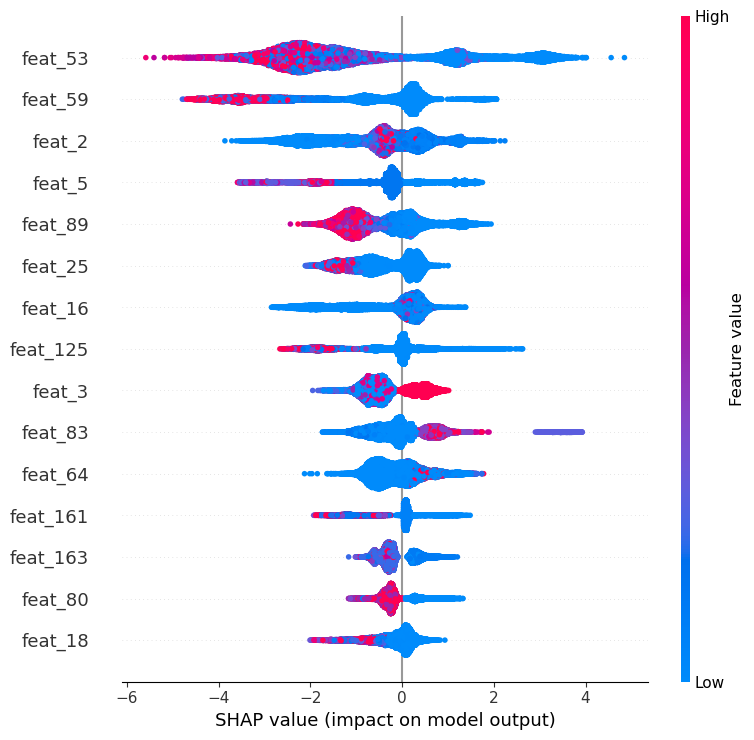

In [15]:
final_shap = shap.TreeExplainer(final_model).shap_values(labeled[final_cols])
mean_abs = pd.Series(np.abs(final_shap).mean(axis=0), index=final_cols).sort_values(ascending=False)
shap_report = pd.DataFrame({"mean_abs_shap": mean_abs, "shap_share": mean_abs / mean_abs.sum()})
graph_cols = [c for c in final_cols if not c.startswith("feat_")]
print(shap_report.head(15).round(4))
print("\ngraph features by SHAP rank:", {c: int(mean_abs.index.get_loc(c)) + 1 for c in graph_cols})
shap.summary_plot(final_shap, labeled[final_cols], max_display=15, show=True)